# Is the predicted error of LF-NS right?

A single LF-NS run reports an evidence estimate **and** a standard deviation for it, without any repetition. This notebook checks that prediction the direct way: it repeats runs with different seeds on a problem with a known evidence and compares the spread of the estimates with what each run predicted.

1. The distribution of `ln Z` over repeated runs
2. Predicted against observed error for different numbers of live points
3. The bias of the estimator
4. The batch size `r`: parallel speed-up against error

The test problem is the one of appendix S2.2 of the paper: a one-dimensional likelihood `l(u) = 100 exp(-100 u)` on the unit interval, with evidence `Z = 1 - exp(-100)`, which is 1 to 43 digits.

To run: `uv sync` in the repository root, then `uv run jupyter lab`. The notebook performs about a thousand runs and takes one to two minutes.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

import lfns
import notebook_style as style

style.apply()
OBSERVED, PREDICTED = style.BLUE, style.ORANGE  # fixed colour per quantity throughout

RATE = 100.0
LOG_EVIDENCE = np.log1p(-np.exp(-RATE))  # exact ln Z, zero to machine precision

def log_likelihood(unit_point, seed):
    return np.log(RATE) - RATE * unit_point[0]

def repeat_runs(n_live, n_replaced, n_runs):
    # Runs with seeds 0 .. n_runs - 1; returns ln Z, predicted relative std, iterations, evaluations.
    # One dimension needs few Gibbs sweeps; 20 keeps a thousand runs affordable.
    results = [lfns.run(log_likelihood, 1, n_live=n_live, n_replaced=n_replaced, seed=seed, n_sweeps=20)
               for seed in range(n_runs)]
    return (np.array([r.log_evidence for r in results]), np.array([r.relative_std for r in results]),
            np.array([r.n_iterations for r in results]), np.array([r.n_proposals for r in results]))

## 1. The distribution of `ln Z` over repeated runs

300 runs with 100 live points, replacing 10 per iteration. If the prediction is right, the estimates scatter around the exact value with a standard deviation equal to the predicted one. (For a small relative error, the standard deviation of `ln Z` equals the relative standard deviation of `Z`.)

300 runs in 18.1 s
observed std of ln Z:      0.199
mean predicted std:        0.201   (ranges from 0.187 to 0.213)
mean of ln Z - exact:      +0.016 +- 0.012
runs within 1 predicted std: 68%   (a normal error would give 68%)
runs within 2 predicted std: 95%   (a normal error would give 95%)


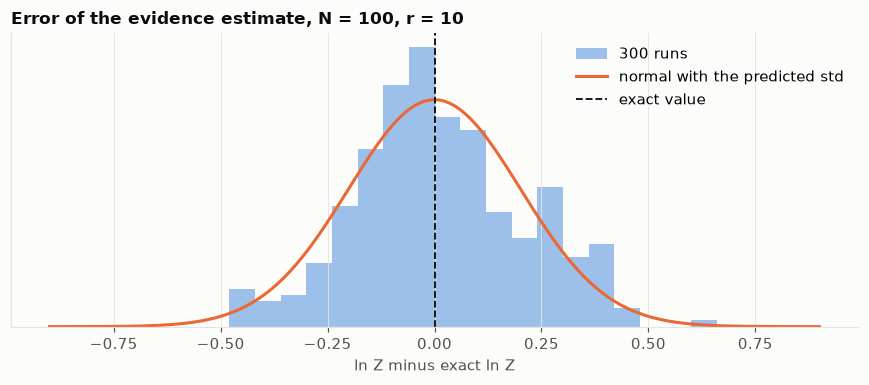

In [2]:
start = time.perf_counter()
log_z, predicted_std, _, _ = repeat_runs(n_live=100, n_replaced=10, n_runs=300)
print(f"300 runs in {time.perf_counter() - start:.1f} s")

errors = log_z - LOG_EVIDENCE
print(f"observed std of ln Z:      {errors.std(ddof=1):.3f}")
print(f"mean predicted std:        {predicted_std.mean():.3f}   (ranges from {predicted_std.min():.3f} to {predicted_std.max():.3f})")
print(f"mean of ln Z - exact:      {errors.mean():+.3f} +- {errors.std(ddof=1) / np.sqrt(len(errors)):.3f}")
for n_sigma, expected in [(1, 0.683), (2, 0.954)]:
    inside = np.mean(np.abs(errors) < n_sigma * predicted_std)
    print(f"runs within {n_sigma} predicted std: {100 * inside:.0f}%   (a normal error would give {100 * expected:.0f}%)")

grid = np.linspace(-0.9, 0.9, 400)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(errors, bins=30, range=(-0.9, 0.9), density=True, color=OBSERVED, alpha=0.45, label="300 runs")
ax.plot(grid, stats.norm.pdf(grid, 0.0, predicted_std.mean()), color=PREDICTED, label="normal with the predicted std")
ax.axvline(0.0, color=style.INK, lw=1.2, ls="--", label="exact value")
ax.set_xlabel("ln Z minus exact ln Z"); ax.set_yticks([]); ax.set_title("Error of the evidence estimate, N = 100, r = 10")
ax.legend()
fig.tight_layout()

## 2. Predicted against observed error for different numbers of live points

The number of live points `N` sets how precise a run can be. Here `N` varies from 25 to 800 with `r = N / 10`, 100 runs each.

600 runs in 66.7 s


    N   observed   predicted   ratio
   25      0.421       0.392    0.93
   50      0.315       0.283    0.90
  100      0.191       0.201    1.05
  200      0.151       0.143    0.95
  400      0.101       0.103    1.02
  800      0.072       0.074    1.03


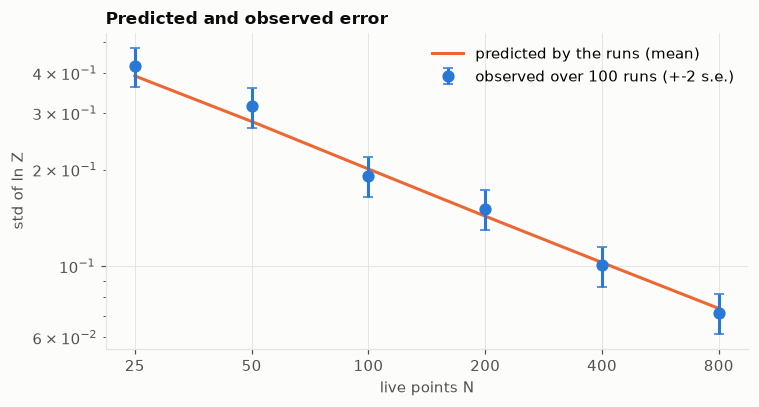

In [3]:
live_counts = [25, 50, 100, 200, 400, 800]
N_RUNS = 100
by_live_count = {}
start = time.perf_counter()
for n_live in live_counts:
    by_live_count[n_live] = repeat_runs(n_live, n_live // 10, N_RUNS)
print(f"{len(live_counts) * N_RUNS} runs in {time.perf_counter() - start:.1f} s")

observed = np.array([by_live_count[n][0].std(ddof=1) for n in live_counts])
# Standard error of a standard deviation estimated from n normal draws: std / sqrt(2 (n - 1)).
observed_error = observed / np.sqrt(2.0 * (N_RUNS - 1))
predicted = np.array([by_live_count[n][1].mean() for n in live_counts])

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(live_counts, predicted, color=PREDICTED, label="predicted by the runs (mean)")
ax.errorbar(live_counts, observed, yerr=2 * observed_error, color=OBSERVED, fmt="o", markersize=7, capsize=3,
            label="observed over 100 runs (+-2 s.e.)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(live_counts, [str(n) for n in live_counts]); ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel("live points N"); ax.set_ylabel("std of ln Z"); ax.set_title("Predicted and observed error")
ax.legend()
fig.tight_layout()

print("    N   observed   predicted   ratio")
for n, obs, pred in zip(live_counts, observed, predicted):
    print(f"{n:>5}   {obs:8.3f}   {pred:9.3f}   {pred / obs:5.2f}")

The error falls like `1 / sqrt(N)`, and the prediction follows it. A ratio near 1 means a single run can be trusted to report its own uncertainty.

## 3. The bias of the estimator

The estimator is unbiased when the sequence of dead likelihoods is treated as given. Averaged over runs it is not exactly unbiased: the likelihood of each dead point is correlated with the prior volume at which it died. The resulting bias in `Z` is positive and shrinks like `1 / N`, much faster than the standard deviation, which shrinks like `1 / sqrt(N)`.

    N   relative bias    +-2 s.e.   bias / std
   25          +0.156       0.095         0.37
   50          +0.058       0.066         0.18
  100          +0.036       0.040         0.19
  200          +0.023       0.032         0.15
  400          +0.005       0.020         0.05
  800          +0.004       0.014         0.06


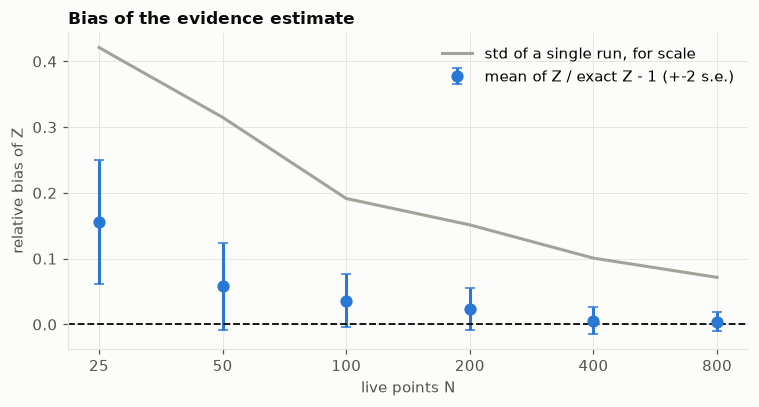

In [4]:
relative_bias = np.array([np.mean(np.exp(by_live_count[n][0] - LOG_EVIDENCE)) - 1.0 for n in live_counts])
bias_error = np.array([np.std(np.exp(by_live_count[n][0] - LOG_EVIDENCE), ddof=1) for n in live_counts]) / np.sqrt(N_RUNS)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(live_counts, observed, color=style.NEUTRAL, label="std of a single run, for scale")
ax.errorbar(live_counts, relative_bias, yerr=2 * bias_error, color=OBSERVED, fmt="o", markersize=7, capsize=3,
            label="mean of Z / exact Z - 1 (+-2 s.e.)")
ax.axhline(0.0, color=style.INK, lw=1.2, ls="--")
ax.set_xscale("log"); ax.set_xticks(live_counts, [str(n) for n in live_counts]); ax.minorticks_off()
ax.set_xlabel("live points N"); ax.set_ylabel("relative bias of Z"); ax.set_title("Bias of the evidence estimate")
ax.legend()
fig.tight_layout()

print("    N   relative bias    +-2 s.e.   bias / std")
for n, bias, error, std in zip(live_counts, relative_bias, bias_error, observed):
    print(f"{n:>5}   {bias:+13.3f}   {2 * error:9.3f}   {bias / std:10.2f}")

The bias is small compared with the spread of a single run at every `N`, so it does not matter for one run. It does matter when many runs are averaged, or when a test asserts that the mean of `Z` equals the exact value.

## 4. The batch size `r`

Each iteration replaces the `r` lowest live points, and those `r` replacements can be evaluated in parallel. A larger `r` means fewer iterations, hence less wall time on a parallel machine, but each iteration shrinks the prior volume in a coarser step. With `N = 100` fixed, `r` varies from 1 (classical nested sampling) to 75.

360 runs in 53.8 s
    r   observed std   predicted std   iterations   evaluations
    1          0.173           0.197          373           570
    5          0.187           0.199           74           565
   10          0.181           0.201           36           556
   25          0.213           0.209           13           524
   50          0.244           0.231            6           481
   75          0.277           0.276            3           406


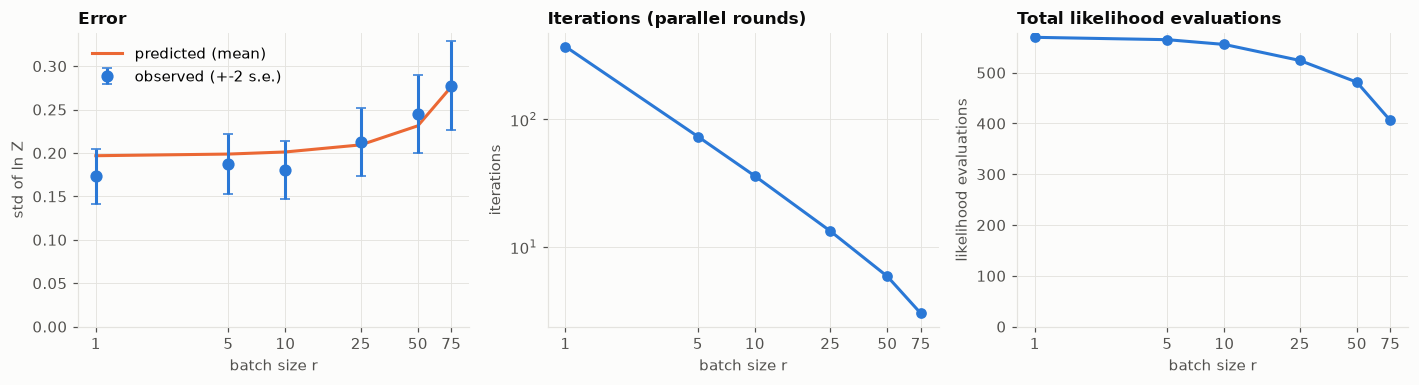

In [5]:
N_LIVE = 100
batch_sizes = [1, 5, 10, 25, 50, 75]
N_BATCH_RUNS = 60
by_batch = {}
start = time.perf_counter()
for n_replaced in batch_sizes:
    by_batch[n_replaced] = repeat_runs(N_LIVE, n_replaced, N_BATCH_RUNS)
print(f"{len(batch_sizes) * N_BATCH_RUNS} runs in {time.perf_counter() - start:.1f} s")

batch_observed = np.array([by_batch[r][0].std(ddof=1) for r in batch_sizes])
batch_error = batch_observed / np.sqrt(2.0 * (N_BATCH_RUNS - 1))
batch_predicted = np.array([by_batch[r][1].mean() for r in batch_sizes])
iterations = np.array([by_batch[r][2].mean() for r in batch_sizes])
evaluations = np.array([by_batch[r][3].mean() for r in batch_sizes])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(batch_sizes, batch_predicted, color=PREDICTED, label="predicted (mean)")
axes[0].errorbar(batch_sizes, batch_observed, yerr=2 * batch_error, color=OBSERVED, fmt="o", markersize=7, capsize=3,
                 label="observed (+-2 s.e.)")
axes[0].set_ylim(bottom=0); axes[0].set_ylabel("std of ln Z"); axes[0].set_title("Error"); axes[0].legend()
axes[1].plot(batch_sizes, iterations, color=OBSERVED, marker="o", markersize=6)
axes[1].set_yscale("log"); axes[1].set_ylabel("iterations"); axes[1].set_title("Iterations (parallel rounds)")
axes[2].plot(batch_sizes, evaluations, color=OBSERVED, marker="o", markersize=6)
axes[2].set_ylim(bottom=0); axes[2].set_ylabel("likelihood evaluations"); axes[2].set_title("Total likelihood evaluations")
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks(batch_sizes, [str(r) for r in batch_sizes]); ax.minorticks_off(); ax.set_xlabel("batch size r")
fig.tight_layout()

print("    r   observed std   predicted std   iterations   evaluations")
for r, obs, pred, its, evals in zip(batch_sizes, batch_observed, batch_predicted, iterations, evaluations):
    print(f"{r:>5}   {obs:12.3f}   {pred:13.3f}   {its:10.0f}   {evals:11.0f}")

Reading the three panels together gives the trade-off. The number of iterations falls in proportion to `1 / r`. The error stays close to that of classical nested sampling up to about `r = N / 4` and rises noticeably beyond. The total number of likelihood evaluations does not increase with `r`. On a machine with `r` cores the wall time is governed by the number of iterations, so a batch of a tenth to a quarter of the live points buys a large speed-up for a small loss of precision.

The prediction tracks the observed error across batch sizes as well, which is the check on the covariance between the prior volumes of the points removed in one iteration.